# Wald test vs. parallel-curves test with and without slide effects (legnini)

Three answers to the morphogen question (Ctrl vs. SHH slides, expression along the distance to SHH+ cells), on the same gene panel and expression layer:

1. **Binned, classic Wald, no slide effects** (`test="wald"`): sliding-window bins, tradeSeq-style Wald test on the posterior-predictive curves (NUTS), p-values from the **Gamma** null fitted to the panel (`gamma_pval`).
2. **Raw cells, parallel-curves test, no slide effects** (`use_binned=False, inference="advi"`): every cell, full-rank ADVI (Laplace start, Adam polish). Cells of a condition are pooled, so the variation between slides is ignored.
3. **Raw cells, parallel-curves test with slide effects** (`bin_obs(sample="sample")`, `inference="advi"`): adds a random level and a random curve per slide. Their two scales are set by empirical Bayes (the mode of their marginal posterior, `slide_scales="empirical_bayes"`), and the p-value uses an F reference with `n_slides - 2` denominator degrees of freedom. On a within-condition split of the SHH slides (no true difference), part 2's model flagged 94% (`tau=0`) / 62% (`tau=0.1`) of genes; modelling slides brings that to the nominal level (see `.claude/advi_plan.md`).

Each part shows the ranked gene table, a p-value histogram and a volcano plot; the end compares the three rankings.

**Before running:** all parts cover the whole 88-gene panel with 4 worker processes. Part 3 is the slowest (the slide effects add ~180 parameters per gene); shorten `GENES` for a trial run, but keep roughly 10+ genes, since the Wald test's Gamma null is fitted to the panel.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

As in the morphogen example: cells in the top percentile of SHH expression are the anchor, and every other cell gets its (normalised) distance to the closest SHH+ cell of its slide. The slide of each cell (`sample`) is part of the design matrix.

In [2]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/legnini23.h5ad")

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
adata.obsm["design_matrix"].head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


## Settings

* `LAYER`: the Normal likelihood suits log-transformed data, so all parts use `log1p_norm` (`None` fits `.X`, as the morphogen example does).
* `TAU`: the smallest shape difference that counts for the parallel-curves test (slope-equivalent units). `0` tests exact parallelism; with `TAU > 0` genes whose shape difference is clearly below it get p-values near 1, so the histogram has a second peak there by design.

In [3]:
LAYER = "log1p_norm"
GENES = list(adata.var_names)  # shorten for a trial run (keep ~10+ genes for the Wald test's Gamma null)
N_WORKERS = 4
TAU = 0.1
timings = {}

In [4]:
def rank_table(stats, pvalue, statistic, columns):
    """Genes ordered by p-value, ties (e.g. p-values that underflow to 0) broken by the larger statistic."""
    table = stats.sort_values([pvalue, statistic], ascending=[True, False])[columns].copy()
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    return table


def qc_plots(stats, title, pvalue=None, pvalue_adj=None):
    """p-value histogram next to the volcano plot; `pvalue`/`pvalue_adj` default to the columns of the test that ran."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    dvg.pl.plot_pvalue_histogram(stats, pvalue=pvalue, ax=axes[0])
    dvg.pl.plot_volcano(stats, pvalue=pvalue, pvalue_adj=pvalue_adj, ax=axes[1], n_label=15)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


PARALLEL_COLUMNS = [
    "shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high",
    "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral", "vi_khat", "vi_ess",
]  # fmt: skip

## 1. Binned data, classic Wald test, Gamma p-values

Sliding windows of radius 0.02 around 51 grid points (`bin_obs` defaults), one GAM per gene sampled with NUTS, Wald statistic on the posterior-predictive condition curves. The p-values come from a Gamma distribution fitted to the lower 90% of the panel's `T` statistics (`gamma_pval`, BH-adjusted `gamma_pval_adj`), so they depend on the panel.

In [5]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50)
wald_stats, _, _ = dvg.tl.fit_model(adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, test="wald", inplace=False)
timings["1: Wald, binned, NUTS"] = time.perf_counter() - t0
print(f"{timings['1: Wald, binned, NUTS']:.0f} s")
wald_table = rank_table(
    wald_stats,
    pvalue="gamma_pval",
    statistic="T",
    columns=["T", "wald_stat", "gamma_pval", "gamma_pval_adj", "empirical_pval", "integral", "rhat_max"],
)
wald_table.head(25)

Fitting DiffSVG models:  51%|█████     | 45/88 [01:47<01:25,  1.98s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [03:23<00:00,  2.32s/it]

204 s


,rank,T,wald_stat,gamma_pval,gamma_pval_adj,empirical_pval,integral,rhat_max
gene,,,,,,,,
PAX7,1,4.899368,64789.337815,2.664535e-15,2.344791e-13,0.0125,-2.173056,1.017679
NKX6.1,2,4.637764,36355.352109,1.376677e-14,6.057377e-13,0.0125,2.100781,1.012364
Circ.RMST,3,1.891341,18067.342831,5.635214e-07,1.324593e-05,0.0125,-1.329157,1.027377
IRX3,4,1.881162,17178.939673,6.020879e-07,1.324593e-05,0.0125,-1.351597,1.013541
GLI3,5,0.685908,4422.841409,1.763604e-03,3.103943e-02,0.0125,-0.810690,1.017027
NEUROG2,6,0.534043,8311.761154,5.180728e-03,7.598402e-02,0.0125,0.640617,1.018136
GLI2,7,0.458736,3851.842681,8.958047e-03,1.126154e-01,0.0125,-0.639237,1.012172
PAX6,8,0.431890,2683.512943,1.091972e-02,1.201169e-01,0.0125,-0.551438,1.018760
PTPRZ1,9,0.271268,3603.970582,3.735342e-02,3.541163e-01,0.0125,-0.482738,1.011578


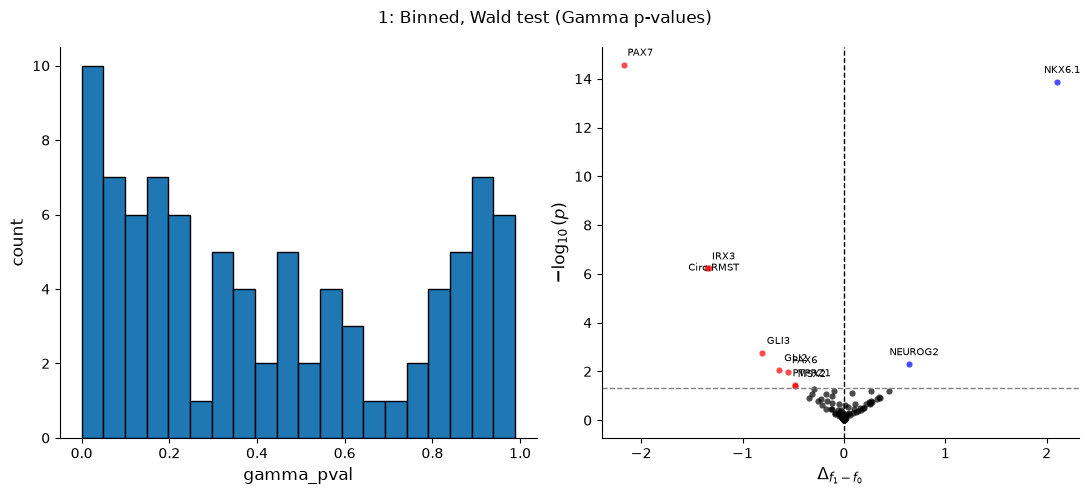

In [6]:
qc_plots(wald_stats, "1: Binned, Wald test (Gamma p-values)", pvalue="gamma_pval", pvalue_adj="gamma_pval_adj");

## 2. Raw cells, parallel-curves test, no slide effects

The binning (contiguous bins) only provides the spline basis and the prediction grid here; the fit uses every cell. `vi_khat` (below ~0.7) and `vi_ess` (above ~0.5) check each gene's approximation against the true posterior.

In [7]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None)
pooled_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["2: curves, cells, ADVI, no slides"] = time.perf_counter() - t0
print(f"{timings['2: curves, cells, ADVI, no slides']:.0f} s")
pooled_stats["vi_trusted"] = (pooled_stats["vi_khat"] < 0.7) & (pooled_stats["vi_ess"] > 0.5)
print(f"{pooled_stats['vi_trusted'].sum()} of {len(pooled_stats)} genes pass the variational diagnostics")
pooled_table = rank_table(pooled_stats, "parallel_pval", "parallel_stat", [*PARALLEL_COLUMNS, "vi_trusted"])
pooled_table.head(25)

Fitting DiffSVG models:   2%|▏         | 2/88 [00:20<11:56,  8.33s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [06:33<00:00,  4.47s/it]

394 s
85 of 88 genes pass the variational diagnostics



/tmp/ipykernel_57206/1773318310.py:3: UserWarning: 3 of 88 genes fail the variational diagnostics (expected: vi_khat < 0.7 and vi_ess > 0.5), so the approximation does not match the posterior for them: do not read their p-values.
  pooled_stats, _, _ = dvg.tl.fit_model(


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,vi_trusted
gene,,,,,,,,,,,,
PAX7,1,1.771784,-1.049524,-1.102262,-0.999123,6261.889601,0.000000e+00,0.000000e+00,-2.167183,0.207713,0.775775,True
HHIP,2,1.470284,1.016162,0.954145,1.075549,3841.301188,0.000000e+00,0.000000e+00,-0.100362,0.229310,0.784461,True
GLI1,3,1.275424,0.939257,0.879250,0.996867,3141.810411,0.000000e+00,0.000000e+00,0.268184,0.226889,0.782856,True
DBX1,4,1.289429,0.696876,0.609798,0.780463,1936.617573,0.000000e+00,0.000000e+00,-0.173251,0.173907,0.802866,True
DBX2,5,0.934258,0.483018,0.417396,0.545941,1909.282850,0.000000e+00,0.000000e+00,-0.308602,0.242377,0.787491,True
FOXA2,6,1.010627,0.478235,0.437536,0.517036,1878.719035,0.000000e+00,0.000000e+00,-0.004395,0.222257,0.763086,True
AC129492.1,7,1.272180,-1.069983,-1.157454,-0.986010,1563.338684,1.217412e-276,1.530461e-275,-0.117657,0.172541,0.803113,True
PTCH1,8,1.440611,0.501819,0.405175,0.594605,1471.718945,6.243663e-264,6.868029e-263,0.084623,0.147752,0.808582,True
FOS,9,0.970804,-0.615020,-0.685128,-0.547873,1448.503305,1.931668e-240,1.888742e-239,-0.050897,0.237103,0.790818,True


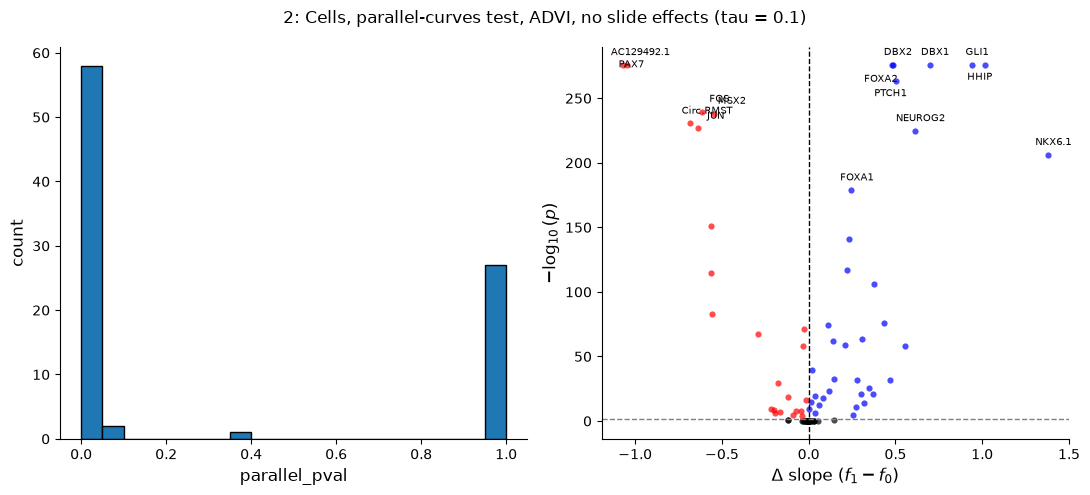

In [8]:
qc_plots(pooled_stats, f"2: Cells, parallel-curves test, ADVI, no slide effects (tau = {TAU})");

## 3. Raw cells, parallel-curves test with empirical-Bayes slide effects

`sample="sample"` adds a random level and a random curve per slide (every slide belongs to one condition; `slide1_A2-2` has no anchor cells and drops out). The two scales of those effects are estimated per gene (`sample_level_sd`, `sample_curve_sd`) and then held fixed while ADVI fits the rest. The p-value uses an F reference with `parallel_df_denominator = n_slides - 2` degrees of freedom; the plotted curves are the population-level ones.

With ~200 parameters per gene the importance-sampling share `vi_ess` is lower even for a good approximation (on simulated slides ~0.45 while matching NUTS), so here `vi_ess > 0.1` together with `vi_khat < 0.7` is the check.

In [9]:
t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None, sample="sample"
)
slides_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    slide_scales="empirical_bayes", test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["3: curves, cells, ADVI, EB slides"] = time.perf_counter() - t0
print(f"{timings['3: curves, cells, ADVI, EB slides']:.0f} s")
slides_stats["vi_trusted"] = (slides_stats["vi_khat"] < 0.7) & (slides_stats["vi_ess"] > 0.1)
print(f"{slides_stats['vi_trusted'].sum()} of {len(slides_stats)} genes pass the variational diagnostics")
slides_table = rank_table(
    slides_stats,
    "parallel_pval",
    "parallel_stat",
    [*PARALLEL_COLUMNS, "sample_level_sd", "sample_curve_sd", "parallel_df_denominator", "vi_trusted"],
)
slides_table.head(25)

Fitting DiffSVG models:   7%|▋         | 6/88 [03:36<49:30, 36.23s/it]  /home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [33:31<00:00, 22.86s/it]

2012 s
88 of 88 genes pass the variational diagnostics


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,sample_level_sd,sample_curve_sd,parallel_df_denominator,vi_trusted
gene,,,,,,,,,,,,,,,
HHIP,1,1.383929,0.910924,0.638617,1.184634,138.587987,0.000101,0.008260,-0.085208,0.097706,0.404064,0.110450,0.277793,14,True
FOXA2,2,0.812904,0.398578,0.182974,0.615921,151.363630,0.000188,0.008260,0.006869,0.090689,0.365969,0.044484,0.220540,14,True
GLI1,3,1.172933,0.832966,0.587908,1.079224,114.281428,0.000407,0.009571,0.276354,0.148722,0.429852,0.096921,0.247894,14,True
PAX7,4,1.485806,-0.905374,-1.289125,-0.512398,93.094506,0.000435,0.009571,-2.115028,0.231869,0.227903,0.207072,0.407721,14,True
NEUROG2,5,1.084901,0.370091,0.060921,0.679444,66.907708,0.002818,0.049595,0.635596,0.211078,0.441419,0.224709,0.313438,14,True
PTCH1,6,1.236055,0.180200,-0.235084,0.597428,46.780245,0.008887,0.118678,0.145253,0.160079,0.370632,0.337614,0.434457,14,True
MSX2,7,0.608092,-0.538885,-0.653635,-0.424896,116.864504,0.009440,0.118678,-0.449460,-0.009082,0.495972,0.146333,0.110829,14,True
FOXA1,8,0.404139,0.193341,0.039602,0.348744,85.322031,0.025010,0.275106,-0.019739,0.241804,0.251561,0.029723,0.158258,14,True
DBX2,9,0.974715,0.632143,0.321033,0.946719,39.806060,0.030811,0.301259,-0.320879,0.172383,0.364833,0.161891,0.321361,14,True


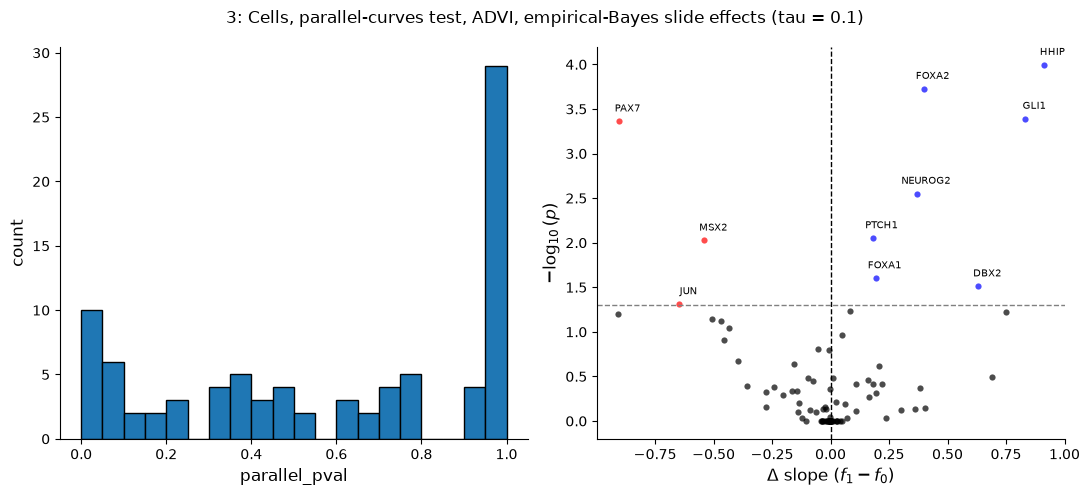

In [10]:
qc_plots(slides_stats, f"3: Cells, parallel-curves test, ADVI, empirical-Bayes slide effects (tau = {TAU})");

In [11]:
slides_stats.loc[~slides_stats["vi_trusted"], ["vi_khat", "vi_ess", "sample_level_sd", "sample_curve_sd", "parallel_pval"]]

,vi_khat,vi_ess,sample_level_sd,sample_curve_sd,parallel_pval
gene,,,,,


## Comparison

How many genes each approach calls, how much the rankings agree (Spearman correlation of the ranks, overlap of the top 20), and how the parallel-curves test's effect sizes and significance change once slides are modelled.

In [12]:
calls = pd.DataFrame(
    {
        "p < 0.05": {
            "1: Wald (Gamma)": int((wald_stats["gamma_pval"] < 0.05).sum()),
            "2: curves, no slides": int((pooled_stats["parallel_pval"] < 0.05).sum()),
            "3: curves, EB slides": int((slides_stats["parallel_pval"] < 0.05).sum()),
        },
        "BH-adjusted < 0.05": {
            "1: Wald (Gamma)": int((wald_stats["gamma_pval_adj"] < 0.05).sum()),
            "2: curves, no slides": int((pooled_stats["parallel_pval_adj"] < 0.05).sum()),
            "3: curves, EB slides": int((slides_stats["parallel_pval_adj"] < 0.05).sum()),
        },
    }
)
display(calls)

ranks = pd.DataFrame(
    {
        "1: Wald (Gamma)": wald_table["rank"],
        "2: curves, no slides": pooled_table["rank"],
        "3: curves, EB slides": slides_table["rank"],
    }
)
print("Spearman correlation of the ranks")
display(ranks.corr(method="spearman").round(3))

top = {name: set(ranks[name].nsmallest(20).index) for name in ranks}
print("Overlap of the top 20 genes")
display(pd.DataFrame({a: {b: len(top[a] & top[b]) for b in top} for a in top}))

pd.Series(timings, name="seconds").round(0).to_frame()

,p < 0.05,BH-adjusted < 0.05
1: Wald (Gamma),10,5
"2: curves, no slides",58,58
"3: curves, EB slides",10,5


Spearman correlation of the ranks


,1: Wald (Gamma),"2: curves, no slides","3: curves, EB slides"
1: Wald (Gamma),1.000,0.866,0.802
"2: curves, no slides",0.866,1.000,0.921
"3: curves, EB slides",0.802,0.921,1.000


Overlap of the top 20 genes


,1: Wald (Gamma),"2: curves, no slides","3: curves, EB slides"
1: Wald (Gamma),20,13,12
"2: curves, no slides",13,20,17
"3: curves, EB slides",12,17,20


,seconds
"1: Wald, binned, NUTS",204.0
"2: curves, cells, ADVI, no slides",394.0
"3: curves, cells, ADVI, EB slides",2012.0


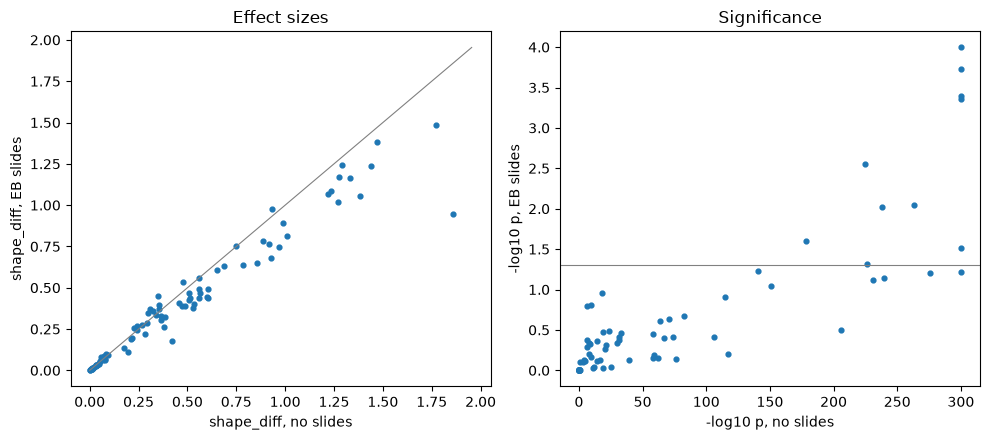

In [13]:
genes = pooled_stats.index
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(pooled_stats["shape_diff"], slides_stats.loc[genes, "shape_diff"], s=12)
lim = float(max(pooled_stats["shape_diff"].max(), slides_stats["shape_diff"].max())) * 1.05
axes[0].plot([0, lim], [0, lim], color="grey", lw=0.8)
axes[0].set(xlabel="shape_diff, no slides", ylabel="shape_diff, EB slides", title="Effect sizes")
floor = 1e-300
axes[1].scatter(
    -np.log10(pooled_stats["parallel_pval"].clip(lower=floor)),
    -np.log10(slides_stats.loc[genes, "parallel_pval"].clip(lower=floor)),
    s=12,
)
axes[1].axhline(-np.log10(0.05), color="grey", lw=0.8)
axes[1].set(xlabel="-log10 p, no slides", ylabel="-log10 p, EB slides", title="Significance")
fig.tight_layout()